<a href="https://colab.research.google.com/github/Andre-Gomez-Serrano/Actividad5Procesamiento/blob/main/actividad5preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Carlos André Gómez Serrano
*   MATRÍCULA: A01733624

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [ ]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [ ]:
#Descarga el archivo: heart_disease.csv y guarda, en un dataframe (cardio_df), todos sus registros.
cardio_df=pd.read_csv('heart_disease.csv')

In [ ]:
#Haz que la columna id sea el índice del dataframe.
cardio_df = cardio_df.set_index('id')
cardio_df.head()

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [ ]:
#Utiliza el método info() del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
cardio_df.info()
num_cols = cardio_df.select_dtypes(include='number').shape[1]
txt_cols = cardio_df.select_dtypes(include='object').shape[1]

print(f"Numéricas: {num_cols}")
print(f"Texto: {txt_cols}")

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB
Numéricas: 7
Texto: 8


In [ ]:
#Determina la cantidad de valores únicos por columna.
cardio_df.nunique()

,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [ ]:
#Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
num_df = cardio_df.select_dtypes(include='number')
unicos = num_df.nunique().sort_values()
print(unicos)

ca            4
num           5
age          50
oldpeak      53
trestbps     60
thalch      119
chol        216
dtype: int64


In [ ]:
#Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

from pandas.api.types import CategoricalDtype
# ca: tiene nulos y es float64, se pasa primero a Int64 (admite nulos) para que las categorías sean 0, 1, 2, 3
ca_tipo = CategoricalDtype(categories=[0, 1, 2, 3], ordered=True)
cardio_df['ca'] = cardio_df['ca'].astype('Int64').astype(ca_tipo)

# num: sin nulos, niveles de 0 a 4
num_tipo = CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True)
cardio_df['num'] = cardio_df['num'].astype(num_tipo)

# Verificación
print(cardio_df[['ca', 'num']].dtypes)
print("\nca:", cardio_df['ca'].cat.categories.tolist(), "| ordenada:", cardio_df['ca'].cat.ordered)
print("num:", cardio_df['num'].cat.categories.tolist(), "| ordenada:", cardio_df['num'].cat.ordered)

print(cardio_df[['ca', 'num']].dtypes)
cardio_df.info()

ca     category
num    category
dtype: object

ca: [0, 1, 2, 3] | ordenada: True
num: [0, 1, 2, 3, 4] | ordenada: True
ca     category
num    category
dtype: object
<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       918 non-null    int64   
 1   sex       918 non-null    object  
 2   origin    918 non-null    object  
 3   cp        918 non-null    object  
 4   trestbps  859 non-null    float64 
 5   chol      888 non-null    float64 
 6   fbs       829 non-null    object  
 7   restecg   918 non-null    object  
 8   thalch    863 non-null    float64 
 9   exang     863 non-null    object  
 10  oldpeak   856 non-null    float64 
 11  slope     610 non-null    object  
 12  ca        309 non-null    category
 13  thal      434 non-null    object  
 14  num       918 non-null    category
dtypes: category(2), float64(4), int64(1), object(8)
me

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [ ]:
#Numéricas
num_df = cardio_df.select_dtypes(include='number')

print(" Estadísticas descriptivas (numéricas) ")
print(num_df.describe().T)

print("\n Sesgo (skewness) ")
print(num_df.skew())

print("\n Curtosis (exceso, Fisher) ")
print(num_df.kurt())

 Estadísticas descriptivas (numéricas) 
          count        mean        std   min    25%    50%    75%    max
age       918.0   53.530501   9.412783  28.0   47.0   54.0   60.0   77.0
trestbps  859.0  132.294529  18.535875  80.0  120.0  130.0  140.0  200.0
chol      888.0  242.189189  53.424806  85.0  216.0  223.0  268.0  603.0
thalch    863.0  137.528389  25.950226  60.0  120.0  140.0  157.0  202.0
oldpeak   856.0    0.880607   1.091840  -2.6    0.0    0.5    1.5    6.2

 Sesgo (skewness) 
age        -0.193710
trestbps    0.630411
chol        1.640672
thalch     -0.209319
oldpeak     1.037990
dtype: float64

 Curtosis (exceso, Fisher) 
age        -0.382511
trestbps    0.632992
chol        6.573848
thalch     -0.483939
oldpeak     1.119834
dtype: float64


In [ ]:
#Categóricas
cat_df = cardio_df.select_dtypes(include=['object', 'category'])

print("\n Estadísticas descriptivas (categóricas) ")
print(cat_df.describe().T)

print("\n Tablas de frecuencia ")
for col in cat_df.columns:
    print(f"\n--- {col} ---")
    frec = cat_df[col].value_counts(dropna=False)
    tabla = pd.DataFrame({
        'frecuencia': frec,
        'porcentaje (%)': (frec / len(cat_df) * 100).round(2)
    })
    print(tabla)


 Estadísticas descriptivas (categóricas) 
        count unique           top freq
sex       918      2          Male  724
origin    918      4     Cleveland  304
cp        918      4  asymptomatic  495
fbs       829      2         False  691
restecg   918      3        normal  551
exang     863      2         False  526
slope     610      3          flat  345
ca        309      4             0  181
thal      434      3        normal  196
num       918      5             0  411

 Tablas de frecuencia 

--- sex ---
        frecuencia  porcentaje (%)
sex                               
Male           724           78.87
Female         194           21.13

--- origin ---
               frecuencia  porcentaje (%)
origin                                   
Cleveland             304           33.12
Hungary               292           31.81
VA Long Beach         200           21.79
Switzerland           122           13.29

--- cp ---
                 frecuencia  porcentaje (%)
cp              

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [ ]:
#Calcula el porcentaje de valores faltantes en cada columna.
faltantes = (cardio_df.isnull().mean() * 100).round(2).sort_values(ascending=False)

tabla_faltantes = pd.DataFrame({
    'nulos': cardio_df.isnull().sum().reindex(faltantes.index),
    'porcentaje (%)': faltantes
})
print(tabla_faltantes)

          nulos  porcentaje (%)
ca          609           66.34
thal        484           52.72
slope       308           33.55
fbs          89            9.69
oldpeak      62            6.75
trestbps     59            6.43
thalch       55            5.99
exang        55            5.99
chol         30            3.27
sex           0            0.00
origin        0            0.00
cp            0            0.00
age           0            0.00
restecg       0            0.00
num           0            0.00


In [ ]:
#Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
umbral = 30
cols_eliminar = faltantes[faltantes > umbral].index.tolist()
print("Columnas a eliminar:", cols_eliminar)

cardio_df = cardio_df.drop(columns=cols_eliminar)
print("\nColumnas restantes:", cardio_df.columns.tolist())
print("Dimensiones:", cardio_df.shape)

Columnas a eliminar: ['ca', 'thal', 'slope']

Columnas restantes: ['age', 'sex', 'origin', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'num']
Dimensiones: (918, 12)


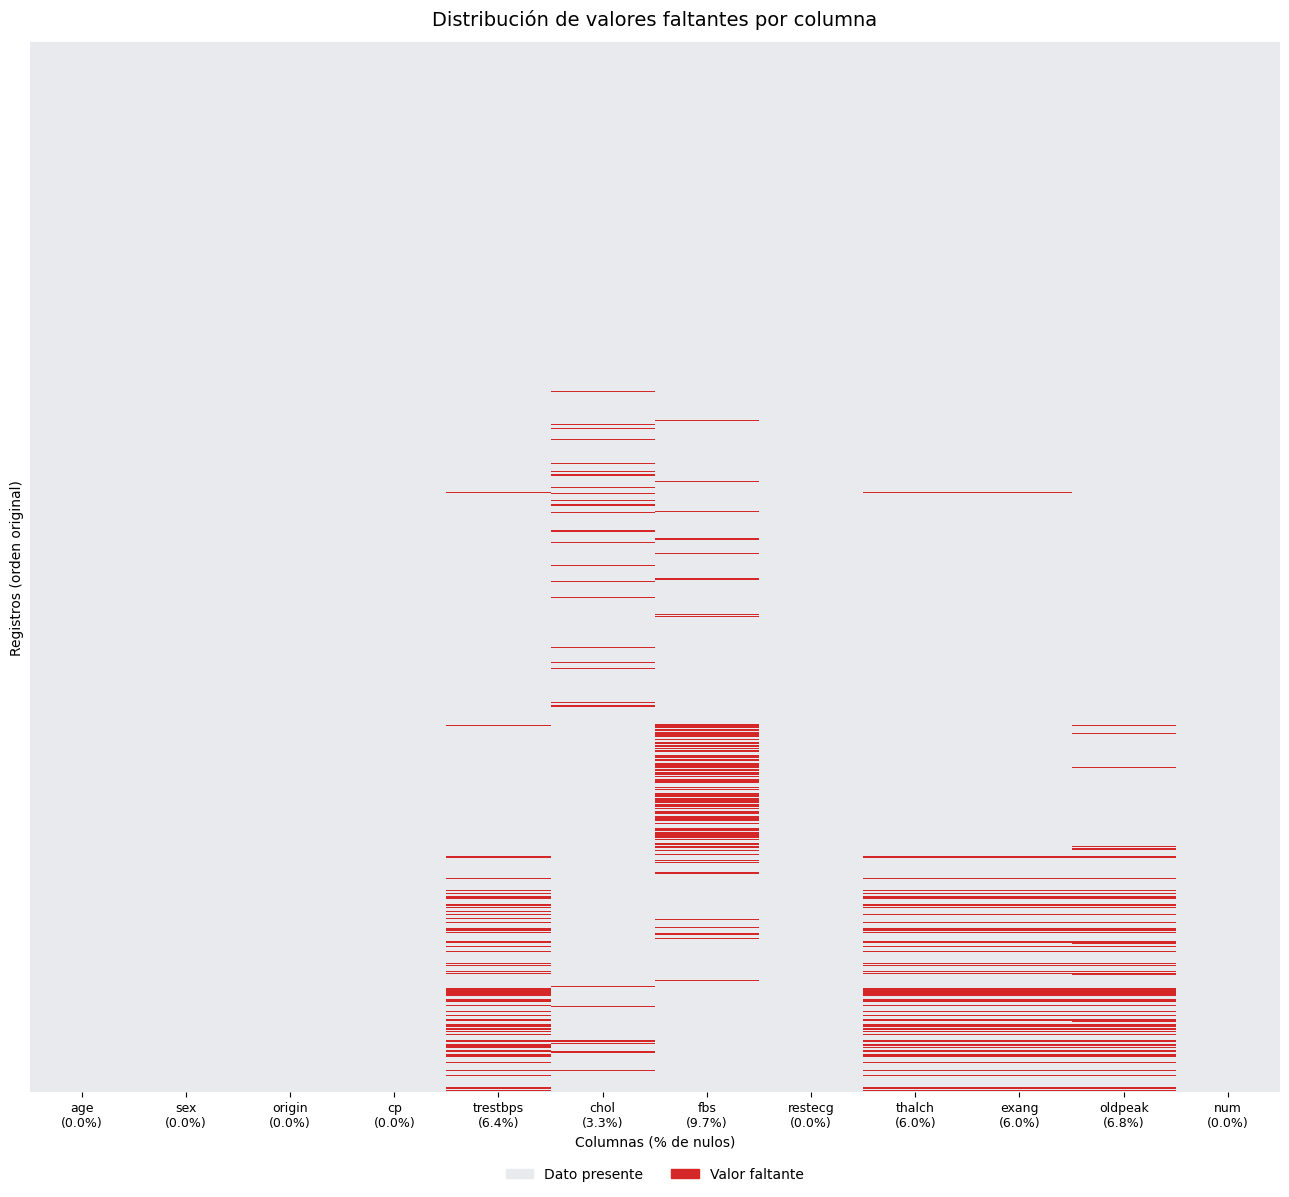

In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Colores: gris claro = dato presente, rojo = faltante
cmap = ListedColormap(['#E8EAED', '#D62728'])

# Etiquetas con el % de nulos por columna
pct = cardio_df.isnull().mean() * 100
etiquetas = [f"{c}\n({p:.1f}%)" for c, p in pct.items()]

# Figura alta para que cada registro tenga más espacio vertical
fig, ax = plt.subplots(figsize=(13, 12))

sns.heatmap(cardio_df.isnull(), cbar=False, cmap=cmap,
            yticklabels=False, linewidths=0, antialiased=False, ax=ax)

ax.set_xticklabels(etiquetas, rotation=0, fontsize=9)
ax.set_title('Distribución de valores faltantes por columna', fontsize=14, pad=12)
ax.set_xlabel('Columnas (% de nulos)')
ax.set_ylabel('Registros (orden original)')

ax.legend(handles=[Patch(color='#E8EAED', label='Dato presente'),
                   Patch(color='#D62728', label='Valor faltante')],
          loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False)

plt.tight_layout()
plt.show()

In [ ]:
#Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

# Solo columnas que tienen nulos
con_nulos = cardio_df.columns[cardio_df.isnull().any()]
nulos = cardio_df[con_nulos].isnull()

# 1) Patrones de faltantes más frecuentes (qué columnas faltan juntas)
patrones = nulos.value_counts().reset_index(name='registros')
patrones = patrones[patrones[con_nulos].any(axis=1)]
print(patrones)

# 2) Correlación entre indicadores de faltante (cercana a 1 = faltan juntas)
print(nulos.astype(int).corr().round(2))

# 3) ¿Dependen los faltantes del origen del paciente?
print(nulos.groupby(cardio_df['origin']).mean().mul(100).round(1))

   trestbps   chol    fbs  thalch  exang  oldpeak  registros
1     False  False   True   False  False    False         85
2      True  False  False    True   True     True         51
3     False   True  False   False  False    False         27
4     False  False  False   False  False     True          4
5     False  False   True   False  False     True          3
6      True  False  False   False  False    False          3
7      True   True  False    True   True     True          3
8      True  False  False    True   True    False          1
9      True  False   True   False  False     True          1
          trestbps  chol   fbs  thalch  exang  oldpeak
trestbps      1.00  0.03 -0.07    0.96   0.96     0.90
chol          0.03  1.00 -0.06    0.03   0.03     0.02
fbs          -0.07 -0.06  1.00   -0.08  -0.08    -0.03
thalch        0.96  0.03 -0.08    1.00   1.00     0.92
exang         0.96  0.03 -0.08    1.00   1.00     0.92
oldpeak       0.90  0.02 -0.03    0.92   0.92     1.00
     

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [ ]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [ ]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

**Variables**

trestbps, thalch, exang y oldpeak: en el bloque inferior del mapa los nulos de estas cuatro caen en las mismas filas.
chol y fbs: se ven nulos en zonas parecidas, aunque fbs tiene además un bloque propio en la parte media. Este vínculo es más débil, así que confirma con la matriz de correlación de faltantes.

**Investigación**

thalch, exang y oldpeak: prueba de esfuerzo. Las tres variables se obtienen de la misma prueba de esfuerzo: la frecuencia cardíaca máxima alcanzada, la angina inducida por el ejercicio y la depresión del segmento ST durante el ejercicio. Si la prueba no se realizó, las tres quedan vacías a la vez. Hay razones clínicas para no hacerla. Las guías de la American Heart Association enumeran contraindicaciones como la angina inestable en curso, la insuficiencia cardíaca descompensada o una discapacidad física que impida una prueba segura (Fletcher et al., 2013). Además, cuando el paciente no logra una respuesta adecuada de frecuencia cardíaca y presión arterial, la prueba pierde valor diagnóstico, lo que puede llevar a no registrarla o a sustituirla por otra modalidad. Las guías más recientes mantienen la prueba de esfuerzo como recomendación de clase 1 para diagnosticar isquemia miocárdica en dolor torácico estable (Gulati et al., 2021), por lo que su ausencia sí es informativa.
Stress testing TRP 2021 Ramer
 +2

trestbps: faltante de naturaleza distinta. La presión arterial en reposo se mide al ingreso y no depende de la prueba de esfuerzo, así que no hay una razón clínica directa para que falte junto con las otras tres. Esto es una inferencia mía, ya que no encontré una fuente que lo explique. Lo más probable es que el origen sea administrativo (campos no capturados en ciertos centros) y no médico.

chol y fbs: estudios de laboratorio. Ambas provienen de análisis de sangre (colesterol sérico y glucosa en ayunas). Si el perfil de laboratorio no se solicitó o no se transcribió, faltan juntas. Esta explicación es conocimiento clínico general y no la respaldé con una fuente en esta búsqueda. Hay evidencia de que el problema es de recolección por centro: en la base de Suiza, el colesterol sérico falta por completo (Engineering Reports, 2025).

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [ ]:
#La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:
#cardio_df['var_with_missing'] = cardio_df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))

import numpy as np

cols_num = ['trestbps', 'chol', 'thalch', 'oldpeak']
cols_cat = ['fbs', 'exang']

# 1) Revisar ceros (informativo)
print("Ceros por columna:")
print((cardio_df[cols_num] == 0).sum())

# 2) Convertir ceros imposibles a NaN (trestbps y chol)
cardio_df[['trestbps', 'chol']] = cardio_df[['trestbps', 'chol']].replace(0, np.nan)

# 3) Imputar numéricas con la mediana por grupo (origin)
for col in cols_num:
    cardio_df[col] = cardio_df.groupby('origin')[col].transform(lambda x: x.fillna(x.median()))
    cardio_df[col] = cardio_df[col].fillna(cardio_df[col].median())  # respaldo: mediana global

# 4) Imputar fbs y exang con la moda por grupo (origin)
for col in cols_cat:
    cardio_df[col] = cardio_df.groupby('origin')[col].transform(
        lambda x: x.fillna(x.mode().iloc[0]) if not x.mode().empty else x)
    cardio_df[col] = cardio_df[col].fillna(cardio_df[col].mode().iloc[0])  # respaldo: moda global

# 5) Verificación
print("\nNulos restantes:")
print(cardio_df.isnull().sum())

Ceros por columna:
trestbps      0
chol          0
thalch        0
oldpeak     369
dtype: int64

Nulos restantes:
age         0
sex         0
origin      0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
num         0
dtype: int64


/tmp/ipykernel_1869/1999353211.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  lambda x: x.fillna(x.mode().iloc[0]) if not x.mode().empty else x)
/tmp/ipykernel_1869/1999353211.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  lambda x: x.fillna(x.mode().iloc[0]) if not x.mode().empty else x)


In [ ]:
#Utiliza la variable restecg para separar los grupos e imputar thalch y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas
cardio_df = pd.read_csv('heart_disease.csv').set_index('id')
cardio_df['num'] = cardio_df['num'].astype(CategoricalDtype([0, 1, 2, 3, 4], ordered=True))
cardio_df = cardio_df.drop(columns=['ca', 'thal', 'slope'])

# Variables con patrón de faltantes similar (prueba de esfuerzo + presión en reposo)
cols_num = ['thalch', 'oldpeak', 'trestbps']
cols_cat = ['exang']   # no numérica: se usa la moda en lugar de la mediana

# trestbps = 0 es imposible fisiológicamente: se trata como faltante
cardio_df['trestbps'] = cardio_df['trestbps'].replace(0, np.nan)

# Numéricas: mediana por grupo de restecg (con respaldo a la mediana global)
for col in cols_num:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.median()))
    cardio_df[col] = cardio_df[col].fillna(cardio_df[col].median())

# Categórica: moda por grupo de restecg (con respaldo a la moda global)
for col in cols_cat:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(
        lambda x: x.fillna(x.mode().iloc[0]) if not x.mode().empty else x)
    cardio_df[col] = cardio_df[col].fillna(cardio_df[col].mode().iloc[0])

# Verificación
print(cardio_df[cols_num + cols_cat].isnull().sum())
print("\nNulos que siguen pendientes:")
print(cardio_df.isnull().sum()[cardio_df.isnull().sum() > 0])

thalch      0
oldpeak     0
trestbps    0
exang       0
dtype: int64

Nulos que siguen pendientes:
chol    30
fbs     89
dtype: int64


/tmp/ipykernel_1869/4121634578.py:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  lambda x: x.fillna(x.mode().iloc[0]) if not x.mode().empty else x)


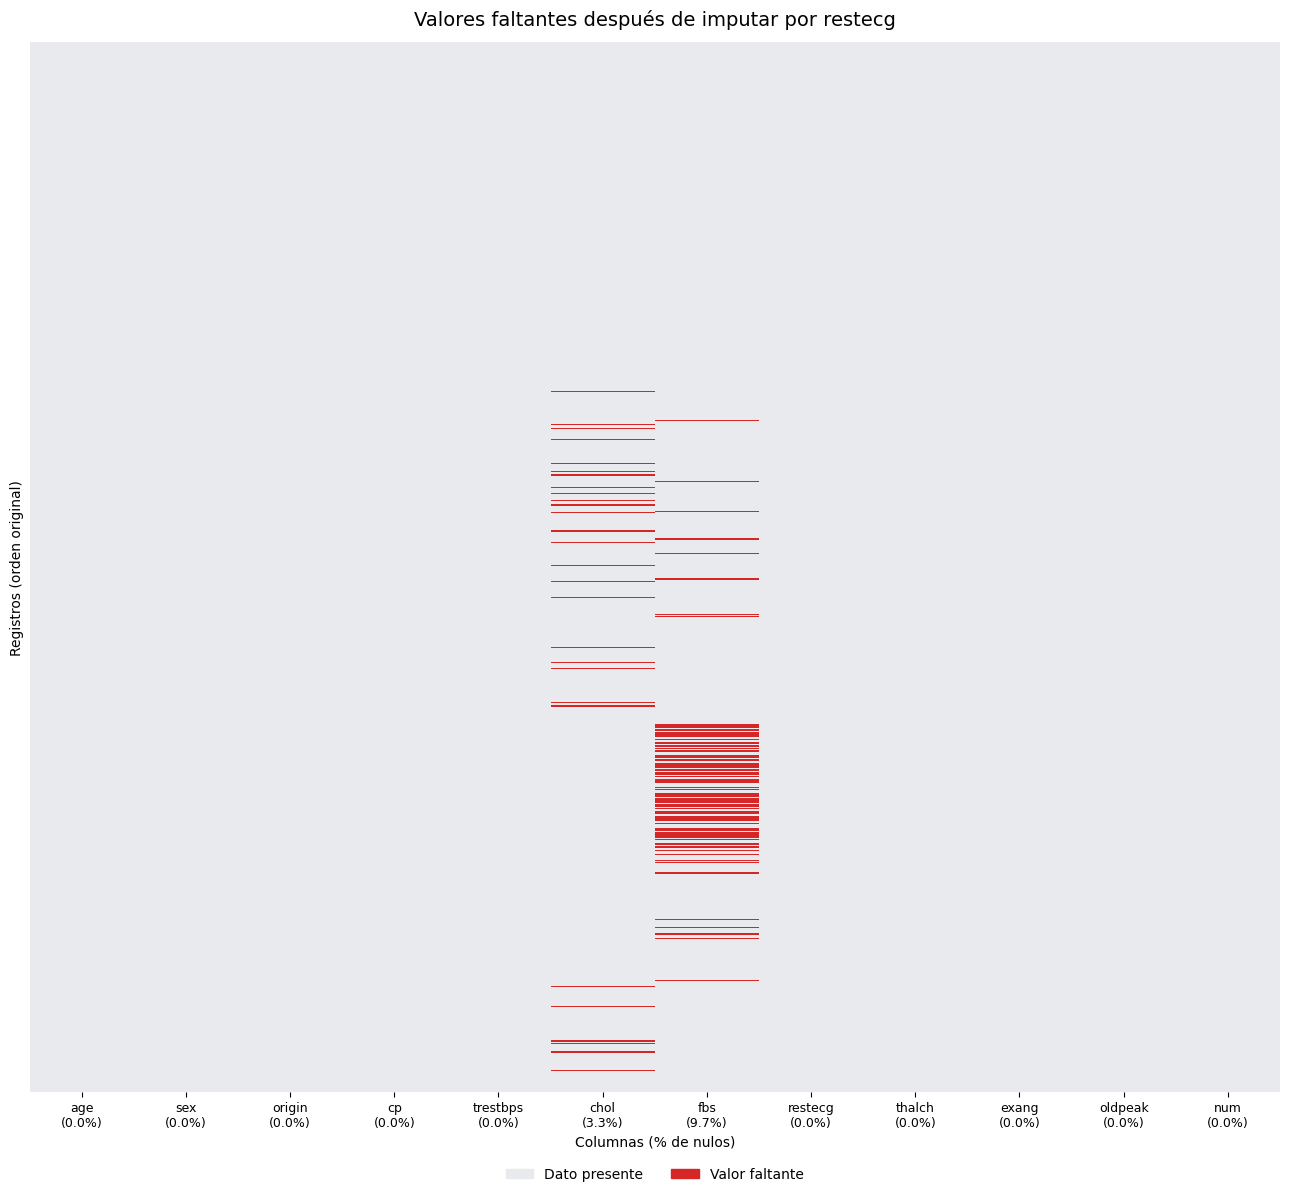

In [ ]:
#Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

cmap = ListedColormap(['#E8EAED', '#D62728'])

pct = cardio_df.isnull().mean() * 100
etiquetas = [f"{c}\n({p:.1f}%)" for c, p in pct.items()]

fig, ax = plt.subplots(figsize=(13, 12))
sns.heatmap(cardio_df.isnull(), cbar=False, cmap=cmap,
            yticklabels=False, linewidths=0, antialiased=False, ax=ax)

ax.set_xticklabels(etiquetas, rotation=0, fontsize=9)
ax.set_title('Valores faltantes después de imputar por restecg', fontsize=14, pad=12)
ax.set_xlabel('Columnas (% de nulos)')
ax.set_ylabel('Registros (orden original)')

ax.legend(handles=[Patch(color='#E8EAED', label='Dato presente'),
                   Patch(color='#D62728', label='Valor faltante')],
          loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False)

plt.tight_layout()
plt.show()

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [ ]:
#Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase SimpleImputer de sklearn
from sklearn.impute import SimpleImputer

# chol = 0 es fisiológicamente imposible: se trata como faltante antes de imputar
cardio_df['chol'] = cardio_df['chol'].replace(0, np.nan)

# Numérica: mediana de toda la columna
imp_num = SimpleImputer(strategy='median')
cardio_df[['chol']] = imp_num.fit_transform(cardio_df[['chol']])

# No numérica: moda (valor más frecuente) de toda la columna
imp_cat = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = imp_cat.fit_transform(cardio_df[['fbs']])

# Verificación
print("Mediana usada en chol:", imp_num.statistics_[0])
print("Moda usada en fbs:", imp_cat.statistics_[0])
print("\nNulos restantes:")
print(cardio_df.isnull().sum())

Mediana usada en chol: 223.0
Moda usada en fbs: False

Nulos restantes:
age         0
sex         0
origin      0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
num         0
dtype: int64


Justifica la estrategia (mean, median, most_frequent) que emplees en cada caso.

Justificación

chol → median

La mediana es resistente a valores extremos, y el colesterol sérico es una variable con cola derecha: hay pacientes con hipercolesterolemia severa que jalan la media hacia arriba.
Si en tu salida la media es mayor que la mediana y el sesgo es positivo, eso lo confirma. Cita esos números en tu justificación.
Además, chol tenía ceros imposibles que se convirtieron a NaN. Aun así, es posible que queden valores atípicos, y la mediana no se ve afectada por ellos.
Imputar con la mediana conserva mejor la forma de la distribución que imputar con una media inflada.

fbs → most_frequent

fbs indica si la glucosa en ayunas es mayor a 120 mg/dl (verdadero o falso). Es una variable binaria, no numérica.
La media y la mediana no tienen sentido en una variable categórica: una media de 0.17 no es ni verdadero ni falso.
La moda es el único estadístico que produce un valor válido de la variable. Si la clase mayoritaria domina (por ejemplo, la mayoría de los pacientes con glucosa normal), la moda es además la suposición más probable para un paciente al azar.

¿Por qué no mean en ninguno?

La media solo sería adecuada con una variable numérica de distribución simétrica y sin atípicos. Aquí chol no cumple eso, y fbs ni siquiera es numérica. Por eso mean no se usó en ningún caso.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

Variables numéricas: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']


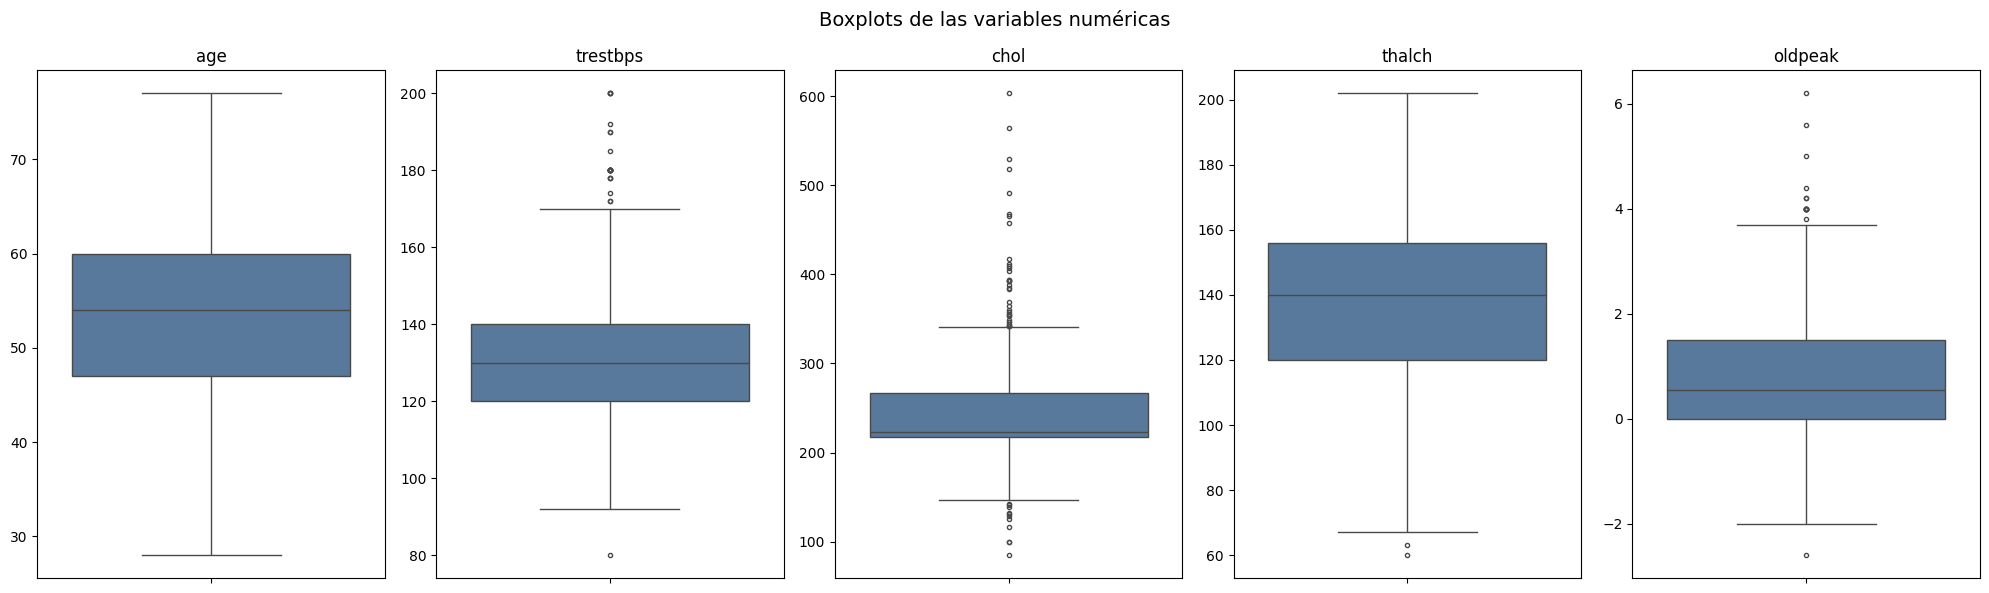

In [ ]:
#Dibuja boxplots de todas las variables numéricas.
num_cols = cardio_df.select_dtypes(include='number').columns.tolist()
print("Variables numéricas:", num_cols)

fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 6))

for ax, col in zip(axes, num_cols):
    sns.boxplot(y=cardio_df[col], ax=ax, color='#4C78A8', fliersize=3)
    ax.set_title(col, fontsize=12)
    ax.set_ylabel('')

fig.suptitle('Boxplots de las variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

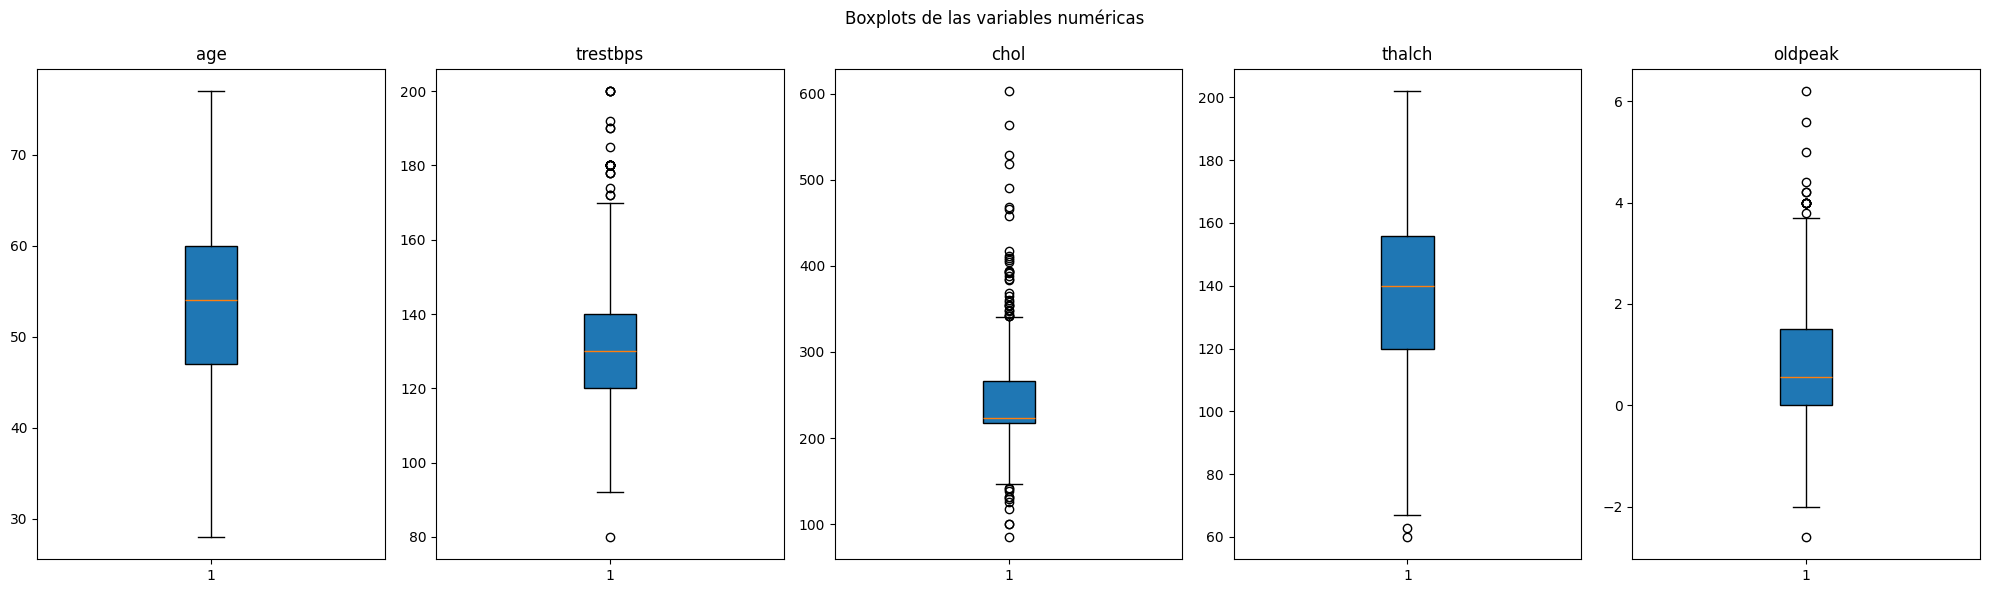


age: 0 atípicos
[]

trestbps: 27 atípicos
[np.float64(80.0), np.float64(172.0), np.float64(174.0), np.float64(178.0), np.float64(180.0), np.float64(185.0), np.float64(190.0), np.float64(192.0), np.float64(200.0)]

chol: 44 atípicos
[np.float64(85.0), np.float64(100.0), np.float64(117.0), np.float64(126.0), np.float64(129.0), np.float64(131.0), np.float64(132.0), np.float64(139.0), np.float64(141.0), np.float64(142.0), np.float64(342.0), np.float64(344.0), np.float64(347.0), np.float64(349.0), np.float64(353.0), np.float64(354.0), np.float64(355.0), np.float64(358.0), np.float64(360.0), np.float64(365.0), np.float64(369.0), np.float64(384.0), np.float64(385.0), np.float64(388.0), np.float64(392.0), np.float64(393.0), np.float64(394.0), np.float64(404.0), np.float64(407.0), np.float64(409.0), np.float64(412.0), np.float64(417.0), np.float64(458.0), np.float64(466.0), np.float64(468.0), np.float64(491.0), np.float64(518.0), np.float64(529.0), np.float64(564.0), np.float64(603.0)]

thalch

In [ ]:
#Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.
import matplotlib.pyplot as plt

num_cols = cardio_df.select_dtypes(include='number').columns.tolist()

fig, ax = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 6))
atipicos = {}

for a, col in zip(ax, num_cols):
    bp = a.boxplot(cardio_df[col].dropna(), patch_artist=True)
    a.set_title(col)

    # 'fliers' contiene los puntos fuera de los bigotes (1.5 * IQR)
    valores = bp['fliers'][0].get_ydata()
    atipicos[col] = valores

plt.suptitle('Boxplots de las variables numéricas')
plt.tight_layout()
plt.show()

# Resumen de atípicos por variable
for col, vals in atipicos.items():
    print(f"\n{col}: {len(vals)} atípicos")
    print(sorted(set(vals)))

# Registros (por id) que son atípicos en cada variable
for col, vals in atipicos.items():
    filas = cardio_df[cardio_df[col].isin(vals)]
    print(f"\n{col}: {len(filas)} registros atípicos")
    print(filas[[col]].head(10))

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [ ]:
#Para la variable trestbps, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
#Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
# Cuartiles
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1

# Límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")

# Valores atípicos: fuera de [límite inferior, límite superior]
atipicos_trestbps = cardio_df[(cardio_df['trestbps'] < limite_inferior) |
                              (cardio_df['trestbps'] > limite_superior)]

print(f"\nCantidad de atípicos: {len(atipicos_trestbps)}")
print(atipicos_trestbps[['trestbps']].sort_values('trestbps'))

Q1: 120.0
Q3: 140.0
IQR: 20.0
Límite inferior: 90.0
Límite superior: 170.0

Cantidad de atípicos: 27
     trestbps
id           
645      80.0
15      172.0
855     172.0
173     174.0
214     178.0
780     178.0
184     178.0
202     180.0
570     180.0
485     180.0
388     180.0
476     180.0
648     180.0
84      180.0
376     180.0
232     180.0
728     180.0
596     180.0
890     180.0
701     185.0
897     190.0
339     190.0
189     192.0
127     200.0
549     200.0
681     200.0
702     200.0


10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

In [ ]:
#Elimina los valores atípicos identificados de la variable trestbps.
print("Registros antes:", len(cardio_df))

cardio_df = cardio_df[(cardio_df['trestbps'] >= limite_inferior) &
                      (cardio_df['trestbps'] <= limite_superior)]

print("Registros después:", len(cardio_df))
print("Atípicos eliminados:", len(atipicos_trestbps))

Registros antes: 918
Registros después: 891
Atípicos eliminados: 27


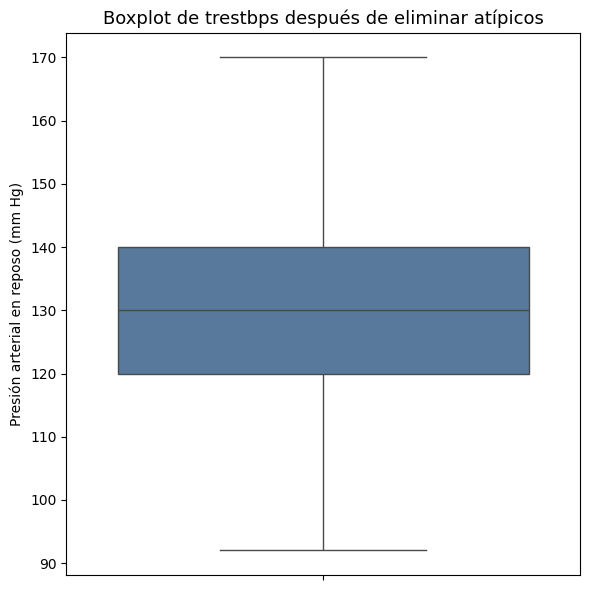

In [ ]:
#Dibuja el boxplot final para visualizar la distribución depurada.

fig, ax = plt.subplots(figsize=(6, 6))
sns.boxplot(y=cardio_df['trestbps'], color='#4C78A8', ax=ax)

ax.set_title('Boxplot de trestbps después de eliminar atípicos', fontsize=13)
ax.set_ylabel('Presión arterial en reposo (mm Hg)')

plt.tight_layout()
plt.show()

---

**Declaración de uso de IA**
ClaudeAI. (2026). *ClaudeIA (basado en Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para generación de código. https://claude.ai/new


Detrano, R., Jánosi, A., Steinbrunn, W., Pfisterer, M., Schmid, J., Sandhu, S., Guppy, K. H., Lee, S., & Froelicher, V. (1989). International application of a new probability algorithm for the diagnosis of coronary artery disease. The American Journal of Cardiology, 64(5), 304–310. https://doi.org/10.1016/0002-9149(89)90524-9

Fletcher, G. F., Ades, P. A., Kligfield, P., Arena, R., Balady, G. J., Bittner, V. A., Coke, L. A., Fleg, J. L., Forman, D. E., Gerber, T. C., Gulati, M., Madan, K., Rhodes, J., Thompson, P. D., & Williams, M. A. (2013). Exercise standards for testing and training: A scientific statement from the American Heart Association. Circulation, 128(8), 873–934. https://doi.org/10.1161/CIR.0b013e31829b5b44

Gulati, M., Levy, P. D., Mukherjee, D., et al. (2021). 2021 AHA/ACC/ASE/CHEST/SAEM/SCCT/SCMR guideline for the evaluation and diagnosis of chest pain. Circulation, 144(22), e368–e454. https://doi.org/10.1161/CIR.0000000000001029

Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1988). Heart disease [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X


---